# Human vs. Machine dialogue classification — SEANCE indices + Random Forest

Classification of human vs. machine (LLM) dialogues using the SEANCE
sentiment/cognition indices and a Random Forest.

# 0. Library imports

All the libraries used in this notebook are imported once here.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

from scipy import stats

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

# 1. SEANCE data preprocessing

In [2]:
seance_csv = "SEANCE/results_human_and_machine_allwords.csv"
n_human = 17_780  # first 17,780 rows = human conversations
n_total = 35_560  # expected total

# Robust read: handles both "," and ", " separators and the
# unnamed index column created when concatenating human/machine
df = pd.read_csv(seance_csv, sep=r",\s*", engine="python")
df.columns = df.columns.str.strip()
assert len(df) == n_total, f"Expected {n_total} dialogues, found {len(df)}"

X = df.iloc[:, 1:252]
X = X.loc[:, ~X.columns.str.startswith("Unnamed")]

# y labels: 0 = human, 1 = machine
y = pd.Series(np.zeros(len(X), dtype=int), name="label")
y.iloc[n_human:] = 1

print(f"X: {X.shape[0]} dialogues × {X.shape[1]} features")
print(f"Labels:\n{y.value_counts().to_string()}")

X: 35560 dialogues × 251 features
Labels:
label
0    17780
1    17780


# 2.a Random Forest: 80% train / 20% test, 5-fold cross-validation — 100 trees

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print(f"Training: {X_train.shape[0]} dialogues — Test: {X_test.shape[0]} dialogues")

rf = RandomForestClassifier(random_state=42)

# 5-fold cross-validation on the training data
cv = cross_validate(
    rf, X_train, y_train, cv=5, n_jobs=-1, scoring=("accuracy", "f1", "roc_auc")
)
print("\nCross-validation (5 folds, training set):")
for m in ("accuracy", "f1", "roc_auc"):
    s = cv[f"test_{m}"]
    print(f"  {m:9s} {s.mean():.4f} ± {s.std():.4f}   {np.round(s, 4)}")

# Final training on the 80%, evaluation on the never-seen 20%
rf = RandomForestClassifier(random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print("\nEvaluation on the test set (20%):")
print(classification_report(y_test, y_pred, target_names=["human", "machine"]))
print("Confusion matrix (rows = actual, columns = predicted):")
cm = pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=["actual human", "actual machine"],
    columns=["predicted human", "predicted machine"],
)
print(cm.to_string())

# Top 15 most discriminative features
imp = pd.Series(rf.feature_importances_, index=X.columns)
print("\nTop 15 features:")
print(imp.sort_values(ascending=False).head(15).round(4).to_string())

Training: 28448 dialogues — Test: 7112 dialogues

Cross-validation (5 folds, training set):
  accuracy  0.9905 ± 0.0010   [0.9907 0.9891 0.9898 0.9917 0.9914]
  f1        0.9906 ± 0.0010   [0.9907 0.9891 0.9898 0.9918 0.9914]
  roc_auc   0.9993 ± 0.0003   [0.9997 0.9994 0.999  0.9994 0.9992]

Evaluation on the test set (20%):
              precision    recall  f1-score   support

       human       0.99      0.99      0.99      3556
     machine       0.99      0.99      0.99      3556

    accuracy                           0.99      7112
   macro avg       0.99      0.99      0.99      7112
weighted avg       0.99      0.99      0.99      7112

Confusion matrix (rows = actual, columns = predicted):
                predicted human  predicted machine
actual human               3518                 38
actual machine               41               3515

Top 15 features:
nwords              0.1888
vader_compound      0.0607
Indadj_GI           0.0569
Self_GI             0.0490
Rcgain_Lass

# 2.b Confusion matrix

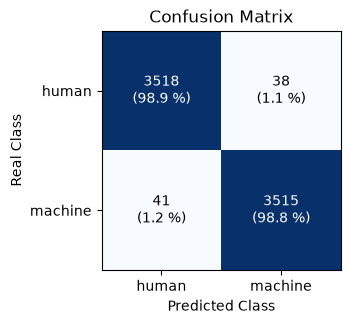

human    — recall: 0.9893 | precision: 0.9885
machine  — recall: 0.9885 | precision: 0.9893


In [4]:
class_names = ["human", "machine"]


def plot_confusion_matrix(
    y_true,
    y_pred,
    labels=None,
    title="Confusion Matrix",
    save_path="confusion_matrix.png",
    dpi=600,
):
    """Plot the confusion matrix: count + % per row (per-class recall).

    Binary or multi-class. Returns (fig, ax).
    Tip: pass y_pred = None to plug in an already-computed matrix.
    """
    if labels is None:
        labels = class_names
    if y_pred is None:
        cm_arr = np.asarray(y_true)  # y_true = pre-computed matrix
    else:
        cm_arr = confusion_matrix(y_true, y_pred, labels=range(len(labels)))
    n = cm_arr.shape[0]

    # % per row — avoids division by zero if a class is missing
    row_sums = cm_arr.sum(axis=1, keepdims=True)
    pct = 100.0 * cm_arr / np.where(row_sums == 0, 1, row_sums)

    fig, ax = plt.subplots(figsize=(1.8 * n, 1.8 * n))
    ax.imshow(cm_arr, cmap="Blues")

    # count + percentage; white text on dark cells
    thresh = cm_arr.max() / 2.0 if cm_arr.max() > 0 else 0.5
    for i in range(n):
        for j in range(n):
            ax.text(
                j,
                i,
                f"{cm_arr[i, j]}\n({pct[i, j]:.1f} %)",
                ha="center",
                va="center",
                color="white" if cm_arr[i, j] > thresh else "black",
            )

    ax.set_xticks(range(n), labels=labels)
    ax.set_yticks(range(n), labels=labels)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Real Class")
    ax.set_title(title)
    fig.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight")
    return fig, ax


fig, ax = plot_confusion_matrix(y_test, y_pred)
plt.show()

# Per-class recall / precision read from the matrix
cm_arr = confusion_matrix(y_test, y_pred)
recall = np.diag(cm_arr) / cm_arr.sum(axis=1)
precision = np.diag(cm_arr) / cm_arr.sum(axis=0)
for name, r, p in zip(class_names, recall, precision):
    print(f"{name:8s} — recall: {r:.4f} | precision: {p:.4f}")

# 2.c Feature importance figure

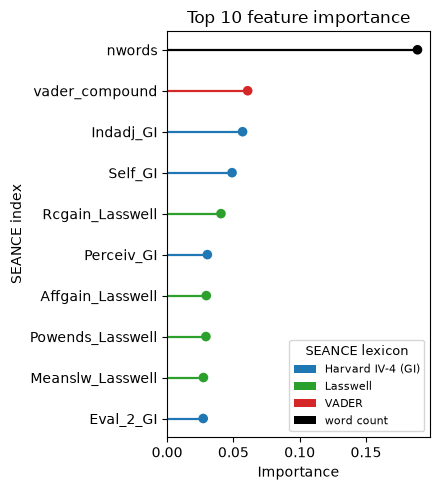

Breakdown of the 10 best features by lexicon:
Harvard IV-4 (GI)    4
Lasswell             4
word count           1
VADER                1


In [5]:
top_n = 10  # number of features displayed

lexicon_colors = {
    "VADER": "#d62728",
    "Harvard IV-4 (GI)": "#1f77b4",
    "Lasswell": "#2ca02c",
    "NRC / EmoLex": "#ff7f0e",
    "GALC": "#9467bd",
    "ANEW": "#17becf",
    "SenticNet": "#e377c2",
    "Hu-Liu": "#8c564b",
    "word count": "#000000",
}


def lexicon_family(name: str) -> str:
    n = name.lower()
    if (
        "nword" in n
        or "n_word" in n
        or "word_count" in n
        or "wordcount" in n
        or "nb_mot" in n
    ):
        return "word count"
    if n.startswith("vader"):
        return "VADER"
    if "_gi" in n:
        return "Harvard IV-4 (GI)"
    if "lasswell" in n:
        return "Lasswell"
    if "nrc" in n or "emolex" in n:
        return "NRC / EmoLex"
    if "galc" in n:
        return "GALC"
    if "anew" in n:
        return "ANEW"
    if "sentic" in n:
        return "SenticNet"
    if "hu" in n and "liu" in n:
        return "Hu-Liu"
    return "ANEW"


# Top features by importance
imp = pd.Series(rf.feature_importances_, index=X.columns)
top_feats = imp.sort_values(ascending=False).head(top_n)
feat = top_feats.iloc[::-1]
fams = [lexicon_family(c) for c in feat.index]
colors = [lexicon_colors[f] for f in fams]
ys = range(len(feat))

fig, ax = plt.subplots(figsize=(4.5, max(5.0, 0.38 * top_n)))
ax.hlines(ys, 0, feat.values, colors=colors, linewidth=1.6, zorder=2)
ax.scatter(
    feat.values, ys, c=colors, s=48, zorder=3, edgecolors="white", linewidths=0.01
)

ax.set_yticks(list(ys), labels=[str(c) for c in feat.index])
ax.set_xlabel("Importance")
ax.set_ylabel("SEANCE index")
ax.set_title(f"Top {top_n} feature importance")
ax.set_xlim(0, feat.max() * 1.05)

present = sorted(set(fams))
handles = [Patch(facecolor=lexicon_colors[f], label=f) for f in present]
ax.legend(
    handles=handles,
    title="SEANCE lexicon",
    loc="lower right",
    fontsize=8,
    title_fontsize=9,
)

fig.tight_layout()
fig.savefig("feature_importances_lollipop.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Breakdown of the {top_n} best features by lexicon:")
print(pd.Series(fams[::-1]).value_counts().to_string())

# 3. Feature-by-feature analysis

Distribution of a chosen feature in the two classes: histogram, boxplots and
empirical cumulative distribution, plus the associated statistical tests.

Descriptive statistics:


,n,mean,std,min,q25,median,q75,max,pct_zeros
group,,,,,,,,,
human,17780,0.0033,0.0086,0.0,0.0000,0.0000,0.0000,0.1290,84.2463
machine,17780,0.0079,0.0069,0.0,0.0031,0.0064,0.0113,0.0529,17.8965


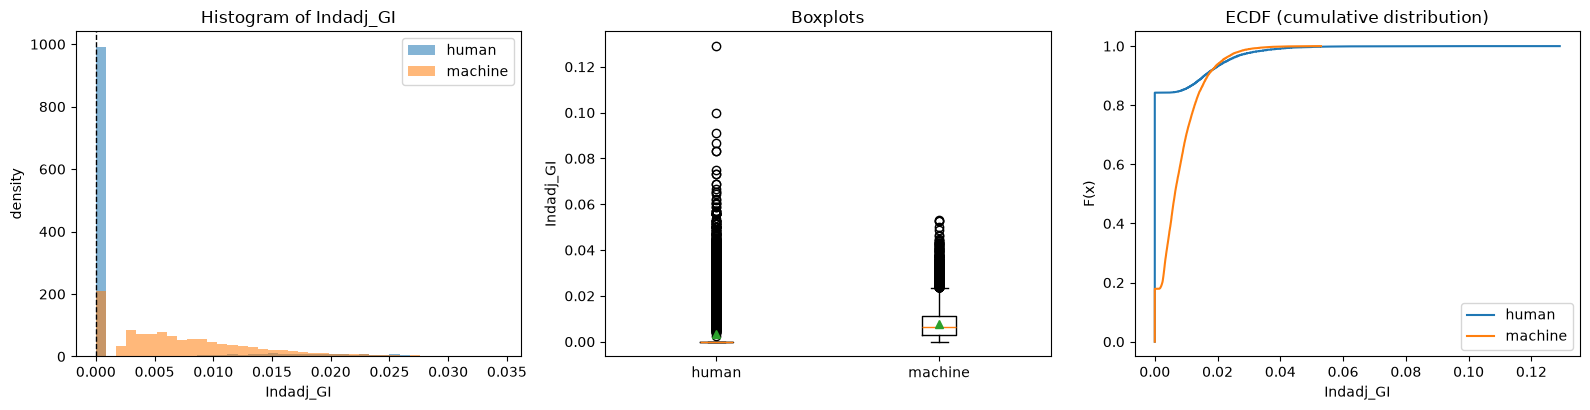

Mann-Whitney: p = 0.00e+00 | KS = 0.6635 (p = 0.00e+00)
Effect size (rank-biserial): 0.5710  (negative → machine tends toward higher values)

Zero spike: human 84.2% vs machine 17.9% — chi² = 15659.1 (p = 0.00e+00)
Non-zero dialogues only: median human 0.0185 vs machine 0.0080 — MW p = 0.00e+00


In [6]:
col = "Indadj_GI"
assert (
    col in X.columns
), f"{col} missing — similar columns: {[c for c in X.columns if 'self' in c.lower()]}"

df_feat = pd.DataFrame({col: X[col].values, "label": y.values})
df_feat["group"] = df_feat["label"].map({0: "human", 1: "machine"})
human = df_feat.loc[df_feat["group"] == "human", col]
machine = df_feat.loc[df_feat["group"] == "machine", col]

# --- 1. Descriptive statistics (with the zero rate: key for a sparse feature) ---
desc = df_feat.groupby("group")[col].agg(
    n="count",
    mean="mean",
    std="std",
    min="min",
    q25=lambda s: s.quantile(0.25),
    median="median",
    q75=lambda s: s.quantile(0.75),
    max="max",
    pct_zeros=lambda s: (s == 0).mean() * 100,
)
print("Descriptive statistics:")
display(desc.round(4))

# --- 2. Visualizations ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
lo, hi = df_feat[col].min(), df_feat[col].quantile(
    0.99
)  # scale to the densest 99%
bins = np.linspace(lo, hi, 41)

axes[0].hist(human, bins=bins, density=True, alpha=0.55, label="human")
axes[0].hist(machine, bins=bins, density=True, alpha=0.55, label="machine")
axes[0].axvline(0, color="k", lw=1, ls="--")
axes[0].set(title=f"Histogram of {col}", xlabel=col, ylabel="density")
axes[0].legend()

axes[1].boxplot([human, machine], showmeans=True)
axes[1].set(title="Boxplots", ylabel=col)
axes[1].set_xticks([1, 2], ["human", "machine"])

for lab, arr in [("human", human), ("machine", machine)]:
    xs = np.sort(arr.values)
    axes[2].plot(xs, np.arange(1, len(xs) + 1) / len(xs), label=lab)
axes[2].set(title="ECDF (cumulative distribution)", xlabel=col, ylabel="F(x)")
axes[2].legend()
fig.tight_layout()
plt.show()

# --- 3. Tests: distributions + zero spike + non-zero subset ---
u_stat, p_mw = stats.mannwhitneyu(human, machine, alternative="two-sided")
ks_stat, p_ks = stats.ks_2samp(human, machine)
rb = 1 - 2 * u_stat / (len(human) * len(machine))

tab = pd.crosstab(df_feat["group"], df_feat[col] == 0)
chi2_z, p_chi_z, _, _ = stats.chi2_contingency(tab)

h_nz, m_nz = human[human > 0], machine[machine > 0]
u_nz, p_nz = stats.mannwhitneyu(h_nz, m_nz, alternative="two-sided")

print(f"Mann-Whitney: p = {p_mw:.2e} | KS = {ks_stat:.4f} (p = {p_ks:.2e})")
print(
    f"Effect size (rank-biserial): {rb:.4f}"
    "  (negative → machine tends toward higher values)"
)
print(
    f"\nZero spike: human {(human == 0).mean() * 100:.1f}% vs machine {(machine == 0).mean() * 100:.1f}%"
    f" — chi² = {chi2_z:.1f} (p = {p_chi_z:.2e})"
)
print(
    f"Non-zero dialogues only: median human {h_nz.median():.4f} vs machine {m_nz.median():.4f}"
    f" — MW p = {p_nz:.2e}"
)

# 4. Greedy ablation experiment

At each iteration, the 5 most important features (Gini importance of the
current Random Forest) are removed, as long as the F1 score on the test set
stays >= 0.90. Once the threshold is crossed, one final evaluation (without
removal) is recorded. The history is saved continuously to CSV.

In [7]:
f1_threshold = 0.90
step = 5  # features removed per iteration
history_file = "ablation_greedy_f1_90_step5.csv"
remaining_file = "ablation_remaining_features.csv"


def greedy_ablation(
    X,
    y,
    f1_threshold=f1_threshold,
    step=step,
    history_file=history_file,
    random_state=42,
    test_size=0.20,
):
    """Greedy ablation: at each iteration, remove the `step` MOST important
    features (Gini importance of the current Random Forest) while F1 on the
    test set stays >= f1_threshold. Once the threshold is crossed, the loop
    performs one final evaluation (without removal) before stopping.

    CSV: one row per removed feature (the `step` features of an iteration
    share the same scores); the final row, without removal, is recorded with
    feature_removed = '—'.
    Returns (hist_df, active_feats).
    """
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=random_state
    )

    active_feats = list(X.columns)
    history = []
    iteration = 0
    threshold_crossed = False
    last_batch = []

    print(f"Starting point: {len(active_feats)} features")

    while True:
        t0 = time.time()
        rf = RandomForestClassifier(random_state=random_state, n_jobs=-1)
        rf.fit(X_train[active_feats], y_train)
        y_pred = rf.predict(X_test[active_feats])
        f1 = f1_score(y_test, y_pred)  # binary F1, class 1 = machine
        acc = accuracy_score(y_test, y_pred)
        imp = pd.Series(rf.feature_importances_, index=active_feats)

        # --- final evaluation once the threshold is crossed:
        #     record the score, remove nothing, stop ---
        if threshold_crossed:
            iteration += 1
            history.append(
                {
                    "iteration": iteration,
                    "n_features_before": len(active_feats),
                    "f1_test": f1,
                    "accuracy_test": acc,
                    "feature_removed": "—",
                    "importance_removed": np.nan,
                }
            )
            pd.DataFrame(history).to_csv(history_file, index=False)
            print(
                f"It. {iteration:3d} | {len(active_feats):3d} feats | F1 = {f1:.4f} | "
                f"final evaluation | {time.time() - t0:.0f}s",
                flush=True,
            )
            break

        # --- normal iteration: remove the `step` most important features ---
        ranked = imp.sort_values(ascending=False)
        batch = list(ranked.index[:step])
        iteration += 1

        if f1 < f1_threshold:
            print(f"\nF1 = {f1:.4f} < {f1_threshold:.2f}: threshold crossed.")
            if last_batch:
                print(f"   Batch that crossed the threshold: {', '.join(last_batch)}")
            threshold_crossed = True

        # one row per removed feature: the 5 of a same iteration
        # share iteration, n_features_before, f1_test and accuracy_test
        for f in batch:
            history.append(
                {
                    "iteration": iteration,
                    "n_features_before": len(active_feats),
                    "f1_test": f1,
                    "accuracy_test": acc,
                    "feature_removed": f,
                    "importance_removed": imp[f],
                }
            )

        # continuous save: nothing is lost if interrupted
        pd.DataFrame(history).to_csv(history_file, index=False)
        print(
            f"It. {iteration:3d} | {len(active_feats):3d} feats | F1 = {f1:.4f} | "
            f"removed: {', '.join(batch)} | {time.time() - t0:.0f}s",
            flush=True,
        )

        last_batch = batch
        active_feats = [f for f in active_feats if f not in set(batch)]
        if not active_feats:
            break  # nothing left to remove

    return pd.DataFrame(history), active_feats


hist, remaining_feats = greedy_ablation(X, y)

print("\nSummary:")
print(f"  Iterations: {hist['iteration'].nunique()}")
below_threshold = hist[hist["f1_test"] < f1_threshold]
if len(below_threshold):
    print(
        f"  First iteration below the threshold: {int(below_threshold['iteration'].min())}"
    )
    print(f"  F1 of the final evaluation: {hist.iloc[-1]['f1_test']:.4f}")
print(f"  Remaining features: {len(remaining_feats)} / {X.shape[1]}")
pd.Series(remaining_feats, name="remaining_features").to_csv(
    remaining_file, index=False
)

Starting point: 251 features
It.   1 | 251 feats | F1 = 0.9889 | removed: nwords, vader_compound, Indadj_GI, Self_GI, Rcgain_Lasswell | 2s
It.   2 | 246 feats | F1 = 0.9859 | removed: Gratitude_GALC, Trngain_Lasswell, Affgain_Lasswell, Eval_2_GI, Rspoth_Lasswell | 3s
It.   3 | 241 feats | F1 = 0.9830 | removed: Meanslw_Lasswell, Powgain_Lasswell, Quality_GI, Wlbgain_Lasswell, Abs_2_GI | 2s
It.   4 | 236 feats | F1 = 0.9854 | removed: Powends_Lasswell, Goal_GI, Natrpro_GI, Perceiv_GI, Pleasur_GI | 3s
It.   5 | 231 feats | F1 = 0.9827 | removed: Powoth_Lasswell, Enlends_Lasswell, Powcon_Lasswell, Exert_GI, Submit_GI | 3s
It.   6 | 226 feats | F1 = 0.9847 | removed: Arousal_GI, Wlbpsyc_Lasswell, Virtue_GI, Exprsv_GI, Rsptot_Lasswell | 3s
It.   7 | 221 feats | F1 = 0.9845 | removed: Positiv_GI, Ritual_GI, Skltot_Lasswell, Our_GI, Place_GI | 2s
It.   8 | 216 feats | F1 = 0.9855 | removed: Tool_GI, Enlgain_Lasswell, Legal_GI, Wlttot_Lasswell, Causal_GI | 3s
It.   9 | 211 feats | F1 = 0.9842 

# 5. Ablation analysis

Maps each removed feature to its SEANCE variable category (Categories.csv),
then displays the F1 evolution and the cumulative number of removed features
per variable category.

Features without a matching category: 0 / 250


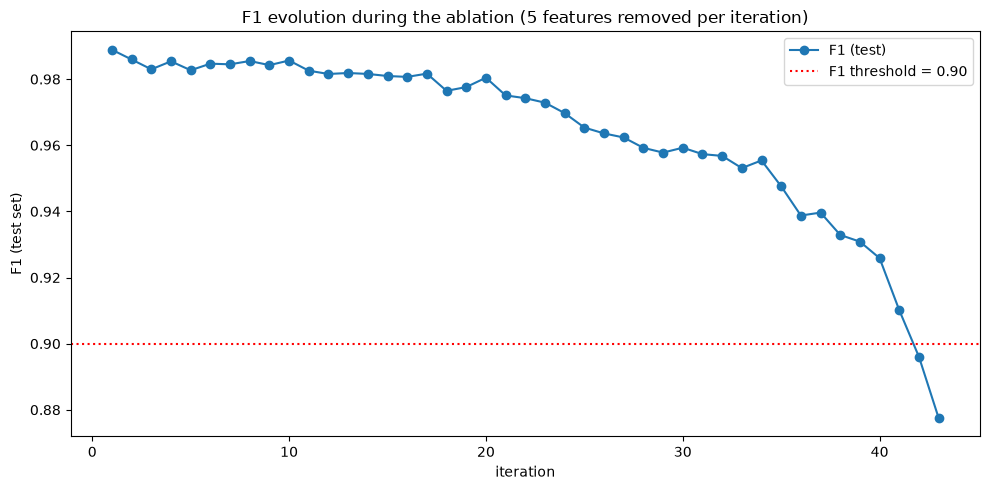

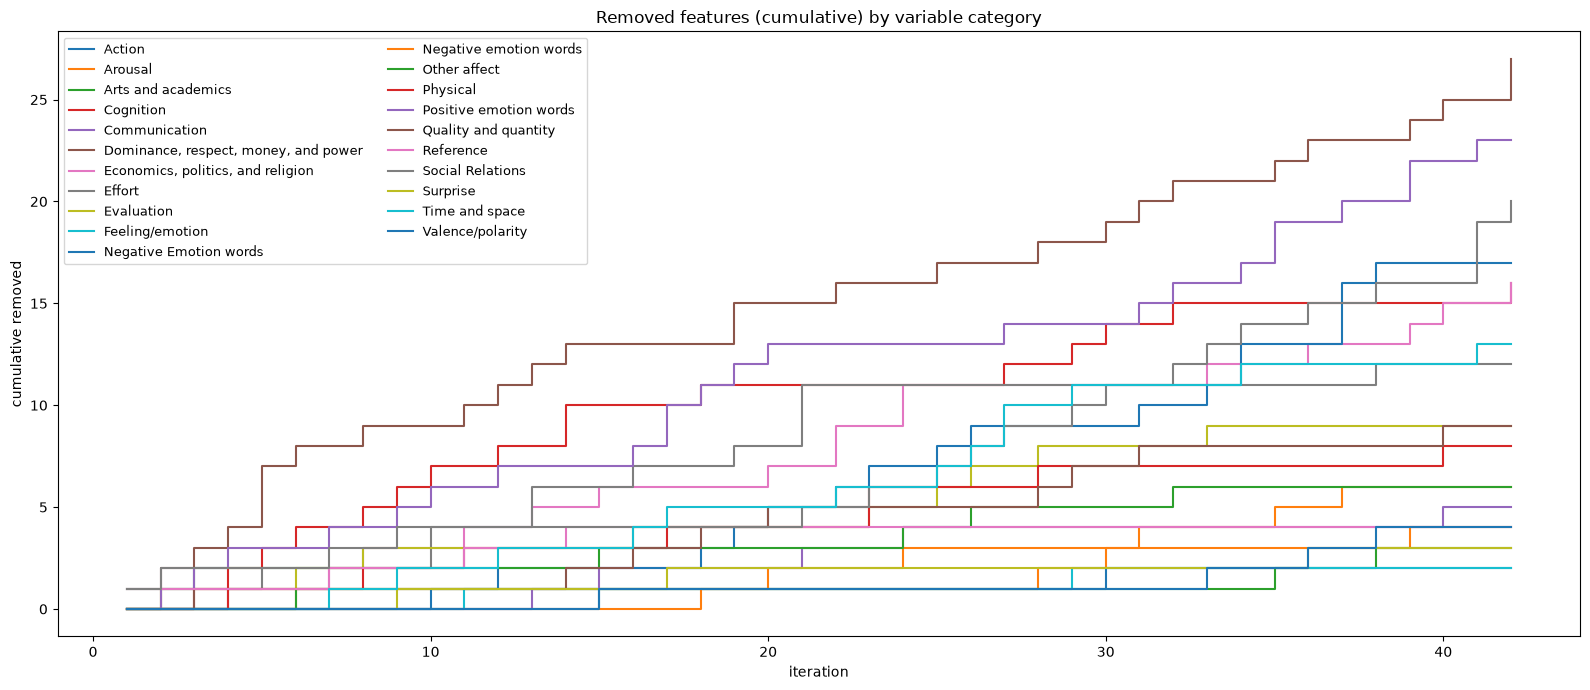

In [8]:
history_file = "ablation_greedy_f1_90_step5.csv"
seance_csv = "SEANCE/results_human_and_machine_allwords.csv"
cat_csv = "donnees_seance/Categories.csv"
f1_threshold = 0.90

hist = pd.read_csv(history_file)

# --- 1. Original order of the 250 base features (header-only read: instant) ---
header = pd.read_csv(seance_csv, sep=r",\s*", engine="python", nrows=0)
header.columns = header.columns.str.strip()
original_order = list(header.columns[2:252])
assert len(original_order) == 250, f"Expected 250 features, found {len(original_order)}"

# --- 2. Variable category of each feature (Categories.csv) ---
mapping = pd.read_csv(cat_csv)
mapping = mapping[["Index", "Variable Category", "List/Index Source"]].drop_duplicates(
    subset="Index"
)
exact = dict(zip(mapping["Index"], mapping["Variable Category"]))
with_src = dict(
    zip(
        mapping["Index"] + "_" + mapping["List/Index Source"].astype(str),
        mapping["Variable Category"],
    )
)
prefixes = sorted(
    zip(mapping["Index"], mapping["Variable Category"]), key=lambda t: -len(t[0])
)


def find_category(f):
    if f in exact:
        return exact[f]
    if f in with_src:
        return with_src[f]
    for i, c in prefixes:
        if f.startswith(i + "_"):
            return c
    return None


hist["variable category"] = hist["feature_removed"].map(find_category)

# Total number of features per category, computed on the 250 original features
cat_per_feature = pd.Series(original_order).map(find_category)
total_per_cat = cat_per_feature.value_counts()
print(f"Features without a matching category: {cat_per_feature.isna().sum()} / 250")

# Depletion iteration: cumulative removals of a category reach its total
hist_sorted = hist.sort_values("iteration").copy()
hist_sorted["cumulative"] = hist_sorted.groupby("variable category").cumcount() + 1
depleted = hist_sorted[
    hist_sorted["cumulative"] == hist_sorted["variable category"].map(total_per_cat)
]
iter_depletion = depleted.groupby("variable category")["iteration"].min()

# --- 3. F1 evolution (one point per iteration of 5 removals) ---
scores = hist.drop_duplicates("iteration")
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(scores["iteration"], scores["f1_test"], "o-", label="F1 (test)")
ax.axhline(f1_threshold, color="red", ls=":", label=f"F1 threshold = {f1_threshold:.2f}")
ax.set(
    title="F1 evolution during the ablation (5 features removed per iteration)",
    xlabel="iteration",
    ylabel="F1 (test set)",
)
ax.legend()
fig.tight_layout()
plt.show()

# --- 4. Cumulative removed features by variable category ---
fig, ax = plt.subplots(figsize=(16, 7))
(
    pd.crosstab(hist["iteration"], hist["variable category"])
    .cumsum()
    .plot(ax=ax, drawstyle="steps-post", legend=True)
)
ax.set(
    title="Removed features (cumulative) by variable category",
    xlabel="iteration",
    ylabel="cumulative removed",
)
ax.legend(loc="upper left", ncol=2, fontsize=9)
fig.tight_layout()
plt.show()

# 6. Categories with the highest cumulative number of removed features

Highlighted categories: dominance, money, positive, cognition.

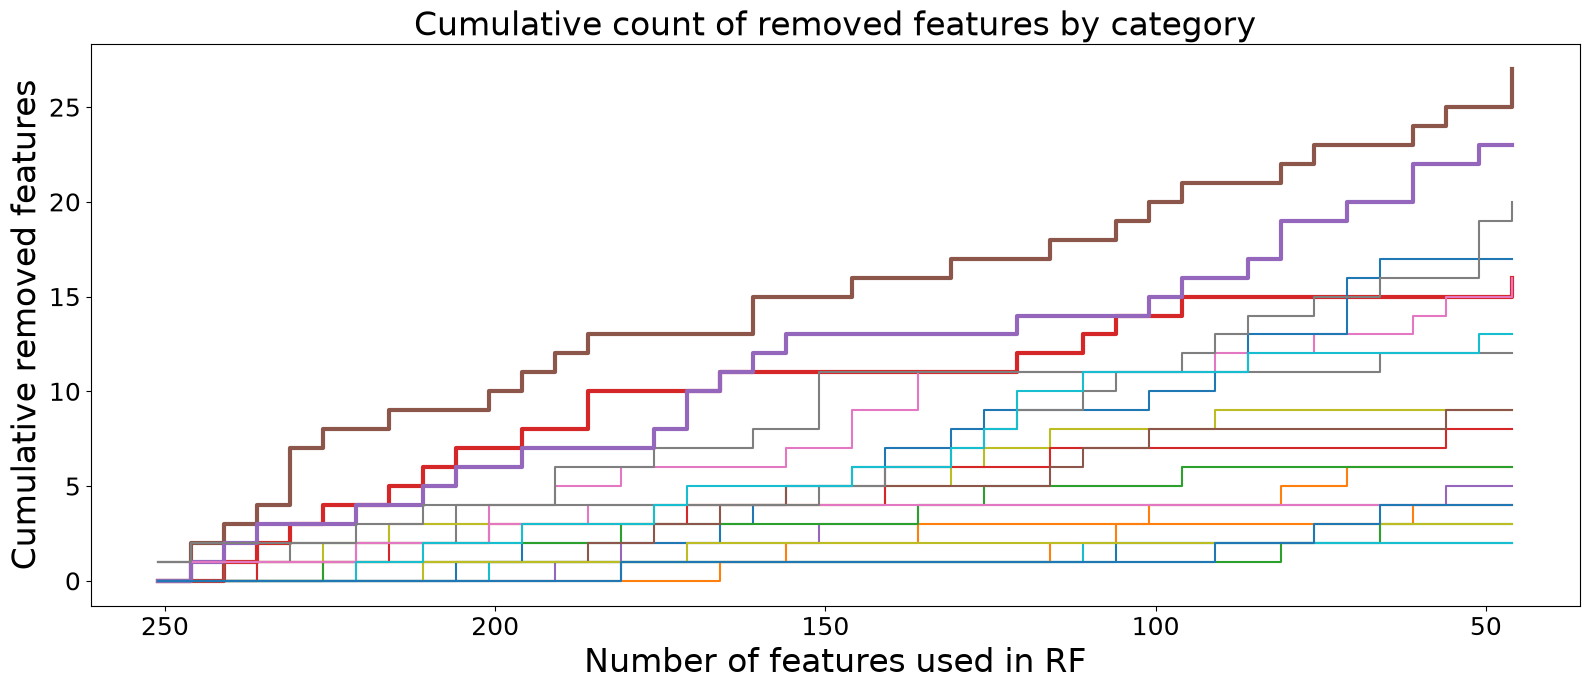

In [9]:
highlight = ["dominance", "money", "positive", "cognition"]

# --- Font sizes (everything is set here) ---
plt.rcParams.update(
    {
        "figure.titlesize": 24,
        "axes.titlesize": 24,
        "axes.labelsize": 24,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
    }
)

fig, ax = plt.subplots(figsize=(16, 7))

ct = pd.crosstab(hist["n_features_before"], hist["variable category"])
ct = ct.sort_index(ascending=False)  # CHRONOLOGICAL order: 251, 246, 241, …
cumul = ct.cumsum()  # cumulative over time, not in x order
cumul.plot(ax=ax, drawstyle="steps-post", legend=False)


def is_highlighted(cat):
    return any(w in str(cat).lower() for w in highlight)


for line in ax.get_lines():
    if is_highlighted(line.get_label()):
        line.set_linewidth(3)

ax.invert_xaxis()  # 251 on the left, decreasing to the right

ax.set(
    title="Cumulative count of removed features by category",
    xlabel="Number of features used in RF",
    ylabel="Cumulative removed features",
)

fig.tight_layout()
plt.savefig("variable_category_removed1.png", dpi=200)
plt.show()

# 7. Categories that were removed quickly

Highlighted categories: reference, action, other affect. The thick line stops
when the category is depleted.

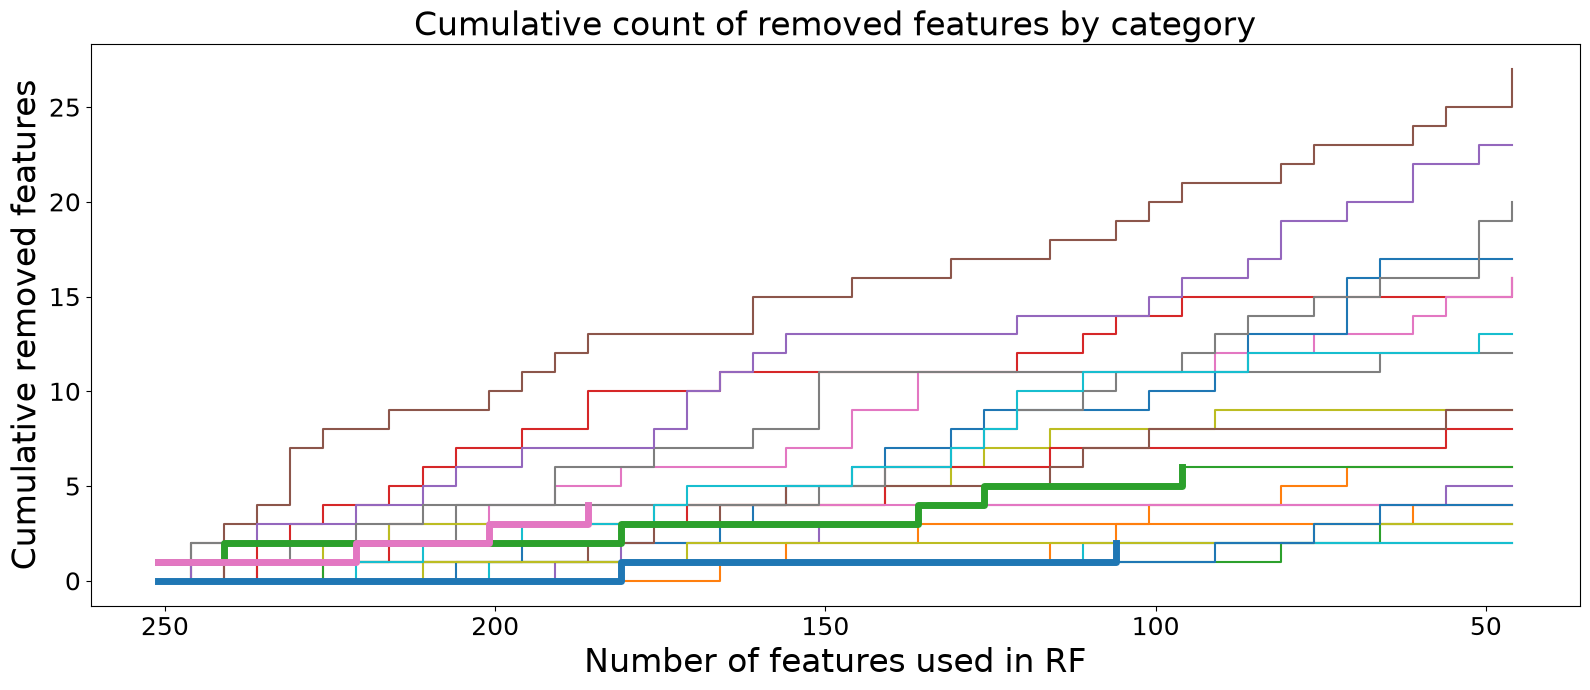

In [10]:
highlight = ["reference", "action", "other affect"]  # ← choose here (empty list = nothing thickened)

# --- Font sizes (everything is set here) ---
plt.rcParams.update(
    {
        "figure.titlesize": 24,
        "axes.titlesize": 24,
        "axes.labelsize": 24,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
    }
)

fig, ax = plt.subplots(figsize=(16, 7))

ct = pd.crosstab(hist["n_features_before"], hist["variable category"])
ct = ct.sort_index(ascending=False)  # CHRONOLOGICAL order: 251, 246, 241, …
cumul = ct.cumsum()  # cumulative over time, not in x order
cumul.plot(ax=ax, drawstyle="steps-post", legend=False)


def is_highlighted(cat):
    return any(w in str(cat).lower() for w in highlight)


# thick line until the category is depleted, not beyond
lines = {l.get_label(): l for l in ax.get_lines()}
for cat, line in lines.items():
    if not is_highlighted(cat):
        continue
    if cat not in iter_depletion.index:
        line.set_linewidth(3)  # never depleted: thick everywhere
        continue
    # x-coordinate (number of features) when the category was emptied
    it_dep = iter_depletion[cat]
    x_stop = hist.loc[hist["iteration"] == it_dep, "n_features_before"].iloc[0]
    portion = cumul[cat]
    portion = portion[portion.index >= x_stop]  # chronological: up to x_stop
    ax.plot(
        portion.index,
        portion.values,
        color=line.get_color(),
        linewidth=5,
        drawstyle="steps-post",
        zorder=3,
    )

ax.invert_xaxis()  # 251 on the left, decreasing to the right

ax.set(
    title="Cumulative count of removed features by category",
    xlabel="Number of features used in RF",
    ylabel="Cumulative removed features",
)

fig.tight_layout()
plt.savefig("variable_category_removed2.png", dpi=200)
plt.show()

# 8. Keep only the lexicons that do not depend on text length

Column selection: VADER and Hu-Liu indices (by name), plus the exact SenticNet
and ANEW index names — their formula does not involve the total word count —
without the `_nwords` variants or the `_neg_3` negation variants.

In [11]:
seance_csv = "SEANCE/results_human_and_machine_allwords.csv"
n_human = 17_780  # first 17,780 rows = human conversations

df = pd.read_csv(seance_csv, sep=r",\s*", engine="python")
df.columns = df.columns.str.strip()

senticnet = ["pleasantness", "attention", "sensitivity", "aptitude", "polarity"]
anew = ["valence", "arousal", "dominance"]
selected_columns = [
    c
    for c in df.columns
    if (
        "vader" in c.lower()
        or "hu_liu" in c.lower()
        or c in senticnet
        or c.lower() in anew
    )
    and not c.endswith("_nwords")
    and "_neg_3" not in c
]

X = df[selected_columns].apply(pd.to_numeric, errors="coerce").fillna(0)
y = np.concatenate(
    [np.zeros(n_human, dtype=int), np.ones(len(df) - n_human, dtype=int)]
)

print(f"X: {X.shape[0]} dialogues × {X.shape[1]} features")

X: 35560 dialogues × 15 features


## 8.b Random Forest on the selected features

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

rf = RandomForestClassifier(random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print(classification_report(y_test, y_pred, target_names=["human", "machine"]))
print("Confusion matrix (rows = actual, columns = predicted):")
print(
    pd.DataFrame(
        confusion_matrix(y_test, y_pred),
        index=["actual human", "actual machine"],
        columns=["predicted human", "predicted machine"],
    )
)

print("\nFeature importances:")
print(
    pd.Series(rf.feature_importances_, index=X.columns)
    .sort_values(ascending=False)
    .round(4)
    .to_string()
)

              precision    recall  f1-score   support

       human       0.95      0.97      0.96      3556
     machine       0.97      0.95      0.96      3556

    accuracy                           0.96      7112
   macro avg       0.96      0.96      0.96      7112
weighted avg       0.96      0.96      0.96      7112

Confusion matrix (rows = actual, columns = predicted):
                predicted human  predicted machine
actual human               3445                111
actual machine              173               3383

Feature importances:
vader_compound     0.4050
hu_liu_prop        0.0817
hu_liu_pos_perc    0.0640
hu_liu_neg_perc    0.0635
vader_positive     0.0486
aptitude           0.0440
attention          0.0430
vader_negative     0.0420
sensitivity        0.0411
pleasantness       0.0380
polarity           0.0371
vader_neutral      0.0358
Valence            0.0278
Dominance          0.0156
Arousal            0.0128


## 8.c Confusion matrix

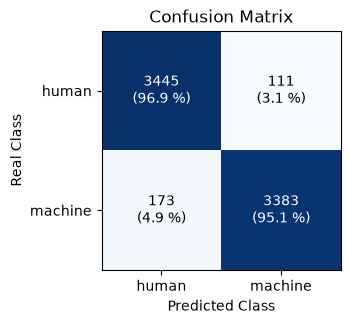

human    — recall: 0.9688 | precision: 0.9522
machine  — recall: 0.9513 | precision: 0.9682


In [13]:
# The ablation figures (sections 6-7) enlarged the global fonts:
# restore matplotlib's default sizes for this figure.
plt.rcdefaults()

fig, ax = plot_confusion_matrix(y_test, y_pred)
plt.show()

# Per-class recall / precision read from the matrix
cm_arr = confusion_matrix(y_test, y_pred)
recall = np.diag(cm_arr) / cm_arr.sum(axis=1)
precision = np.diag(cm_arr) / cm_arr.sum(axis=0)
for name, r, p in zip(class_names, recall, precision):
    print(f"{name:8s} — recall: {r:.4f} | precision: {p:.4f}")

## 8.d Feature importance of the last experiment

Same display as section 2.c, applied to the Random Forest trained above on the
length-independent lexicons (all the selected features are shown, there are
only 15).

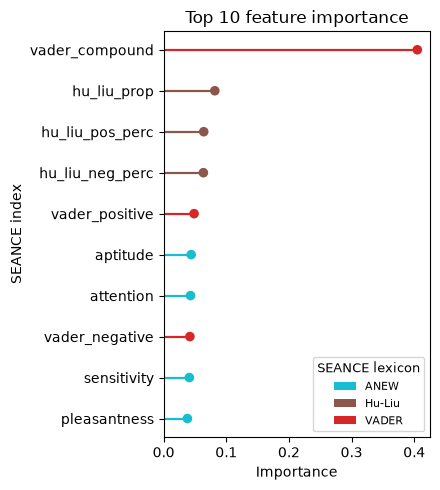

Breakdown of the 10 best features by lexicon:
ANEW      4
VADER     3
Hu-Liu    3


In [14]:
# The current `rf` and `X` are the ones from section 8.b:
# reuse the lollipop display of section 2.c on them.
imp = pd.Series(rf.feature_importances_, index=X.columns)
top_feats = imp.sort_values(ascending=False).head(min(top_n, len(imp)))
feat = top_feats.iloc[::-1]
fams = [lexicon_family(c) for c in feat.index]
colors = [lexicon_colors[f] for f in fams]
ys = range(len(feat))

fig, ax = plt.subplots(figsize=(4.5, max(5.0, 0.38 * top_n)))
ax.hlines(ys, 0, feat.values, colors=colors, linewidth=1.6, zorder=2)
ax.scatter(
    feat.values, ys, c=colors, s=48, zorder=3, edgecolors="white", linewidths=0.01
)

ax.set_yticks(list(ys), labels=[str(c) for c in feat.index])
ax.set_xlabel("Importance")
ax.set_ylabel("SEANCE index")
ax.set_title(f"Top {len(feat)} feature importance")
ax.set_xlim(0, feat.max() * 1.05)

present = sorted(set(fams))
handles = [Patch(facecolor=lexicon_colors[f], label=f) for f in present]
ax.legend(
    handles=handles,
    title="SEANCE lexicon",
    loc="lower right",
    fontsize=8,
    title_fontsize=9,
)

fig.tight_layout()
fig.savefig("feature_importances_selected.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Breakdown of the {len(feat)} best features by lexicon:")
print(pd.Series(fams[::-1]).value_counts().to_string())
